<a href="https://colab.research.google.com/github/G-Chandrabhan/MLweek01/blob/main/project1_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
np.random.seed(42)

In [2]:
import pandas as pd

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

columns = [
    "age", "workclass", "fnlwgt", "education", "education.num",
    "marital.status", "occupation", "relationship", "race", "sex",
    "capital.gain", "capital.loss", "hours.per.week", "native.country", "income"
]

df = pd.read_csv(url, header=None, names=columns, skipinitialspace=True)

print(df.sample(10).to_markdown())

|       |   age | workclass        |   fnlwgt | education    |   education.num | marital.status     | occupation        | relationship   | race   | sex    |   capital.gain |   capital.loss |   hours.per.week | native.country   | income   |
|------:|------:|:-----------------|---------:|:-------------|----------------:|:-------------------|:------------------|:---------------|:-------|:-------|---------------:|---------------:|-----------------:|:-----------------|:---------|
| 14160 |    27 | Private          |   160178 | Some-college |              10 | Divorced           | Adm-clerical      | Not-in-family  | White  | Female |              0 |              0 |               38 | United-States    | <=50K    |
| 27048 |    45 | State-gov        |    50567 | HS-grad      |               9 | Married-civ-spouse | Exec-managerial   | Wife           | White  | Female |              0 |              0 |               40 | United-States    | <=50K    |
| 28868 |    29 | Private          |   1

R1 — Dataset overview

In [3]:
print(f"The data set contain '{df.shape}' rows x columns \n")
print(f"The dataset contain this columsn\n {list(df.columns)} \n")
print(f"DataType of columns \n'{df.dtypes}'")

The data set contain '(32561, 15)' rows x columns 

The dataset contain this columsn
 ['age', 'workclass', 'fnlwgt', 'education', 'education.num', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'capital.gain', 'capital.loss', 'hours.per.week', 'native.country', 'income'] 

DataType of columns 
'age                int64
workclass         object
fnlwgt             int64
education         object
education.num      int64
marital.status    object
occupation        object
relationship      object
race              object
sex               object
capital.gain       int64
capital.loss       int64
hours.per.week     int64
native.country    object
income            object
dtype: object'


In [4]:
# One Row represents one person from 1994 census sample
# There is no id column, so for the "uniqueness of any id column" so we cant clearly differnciate weather their are duplicate records or not
print(df.duplicated().sum())

24


1.   The dataset i am using which is Adult Census income is collect from kaggle by me , but the Actual Dataset itself is extracted from the 1994 Census bureau database by Ronny Kohavi and Barry Becker
2.   The licesen of the dataset listed on kaggle page is manage by CC0 1.0 Universal (https://creativecommons.org/publicdomain/zero/1.0/)





R2 — Data quality audit

In [5]:
# Missing value per column , count and percentage
temp_df = df.replace("?", np.nan)
for col in df.columns:
  nan_count = temp_df[col].isna().sum()
  print(f"the dataset col '{col}' contain '{nan_count}' Nan Values / {((nan_count/len(df))*100).round(2)} % empty ")

the dataset col 'age' contain '0' Nan Values / 0.0 % empty 
the dataset col 'workclass' contain '1836' Nan Values / 5.64 % empty 
the dataset col 'fnlwgt' contain '0' Nan Values / 0.0 % empty 
the dataset col 'education' contain '0' Nan Values / 0.0 % empty 
the dataset col 'education.num' contain '0' Nan Values / 0.0 % empty 
the dataset col 'marital.status' contain '0' Nan Values / 0.0 % empty 
the dataset col 'occupation' contain '1843' Nan Values / 5.66 % empty 
the dataset col 'relationship' contain '0' Nan Values / 0.0 % empty 
the dataset col 'race' contain '0' Nan Values / 0.0 % empty 
the dataset col 'sex' contain '0' Nan Values / 0.0 % empty 
the dataset col 'capital.gain' contain '0' Nan Values / 0.0 % empty 
the dataset col 'capital.loss' contain '0' Nan Values / 0.0 % empty 
the dataset col 'hours.per.week' contain '0' Nan Values / 0.0 % empty 
the dataset col 'native.country' contain '583' Nan Values / 1.79 % empty 
the dataset col 'income' contain '0' Nan Values / 0.0 % 

In [6]:
print("Total duplicated rows:", df.duplicated().sum())

Total duplicated rows: 24


In [7]:
print(f"Numerical column")
print(df.describe().to_markdown())

print("categorical column")
print(df.describe(include="object").to_markdown())

Numerical column
|       |        age |          fnlwgt |   education.num |   capital.gain |   capital.loss |   hours.per.week |
|:------|-----------:|----------------:|----------------:|---------------:|---------------:|-----------------:|
| count | 32561      |  32561          |     32561       |       32561    |     32561      |       32561      |
| mean  |    38.5816 | 189778          |        10.0807  |        1077.65 |        87.3038 |          40.4375 |
| std   |    13.6404 | 105550          |         2.57272 |        7385.29 |       402.96   |          12.3474 |
| min   |    17      |  12285          |         1       |           0    |         0      |           1      |
| 25%   |    28      | 117827          |         9       |           0    |         0      |          40      |
| 50%   |    37      | 178356          |        10       |           0    |         0      |          40      |
| 75%   |    48      | 237051          |        12       |           0    |         0  

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [9]:
print("Unique values per column:")
print(df.nunique().sort_values())

Unique values per column:
income                2
sex                   2
race                  5
relationship          6
marital.status        7
workclass             9
occupation           15
education            16
education.num        16
native.country       42
age                  73
capital.loss         92
hours.per.week       94
capital.gain        119
fnlwgt            21648
dtype: int64


R3 — Target analysis


Target variable: income

Why sensible: It is the original prediction task of the dataset — predicting whether a person earns more than $50,000 per year based on demographic and employment features.

In [10]:
# Class counts
print(df['income'].value_counts())

# Class percentages
print("\nClass balance (%):")
print(df['income'].value_counts(normalize=True).mul(100).round(2))

income
<=50K    24720
>50K      7841
Name: count, dtype: int64

Class balance (%):
income
<=50K    75.92
>50K     24.08
Name: proportion, dtype: float64


In [11]:
# Temporary numeric encoding only for summary
income_num = df['income'].map({'<=50K': 0, '>50K': 1})

print("Mean (proportion of >50K):", round(income_num.mean(), 4))
print("Median:", income_num.median())
print("Std:", round(income_num.std(), 4))
print("Min:", income_num.min())
print("Max:", income_num.max())

Mean (proportion of >50K): 0.2408
Median: 0.0
Std: 0.4276
Min: 0
Max: 1


Skew

The distribution is right-skewed in the binary sense (majority of people are in the lower income group).
Mean (0.24) is higher than the median (0).

Outliers in the Target
For a binary target (<=50K / >50K) there are no numerical outliers.
All values are valid class labels. There are no extreme or impossible values in the target itself.

R4 — Relationships **bold text**

In [12]:
corr_matrix = df.corr(numeric_only=True)
print(corr_matrix)

                     age    fnlwgt  education.num  capital.gain  capital.loss  \
age             1.000000 -0.076646       0.036527      0.077674      0.057775   
fnlwgt         -0.076646  1.000000      -0.043195      0.000432     -0.010252   
education.num   0.036527 -0.043195       1.000000      0.122630      0.079923   
capital.gain    0.077674  0.000432       0.122630      1.000000     -0.031615   
capital.loss    0.057775 -0.010252       0.079923     -0.031615      1.000000   
hours.per.week  0.068756 -0.018768       0.148123      0.078409      0.054256   

                hours.per.week  
age                   0.068756  
fnlwgt               -0.018768  
education.num         0.148123  
capital.gain          0.078409  
capital.loss          0.054256  
hours.per.week        1.000000  


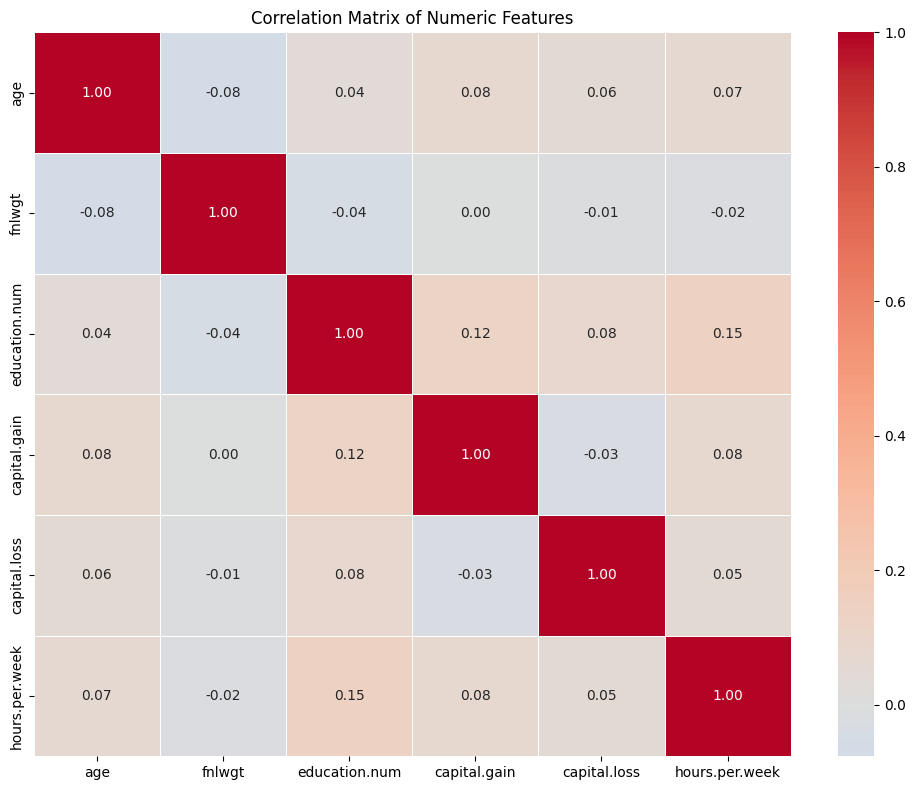

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0,
            fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Numeric Features')
plt.tight_layout()
plt.show()

Target (income) against at least 4 features

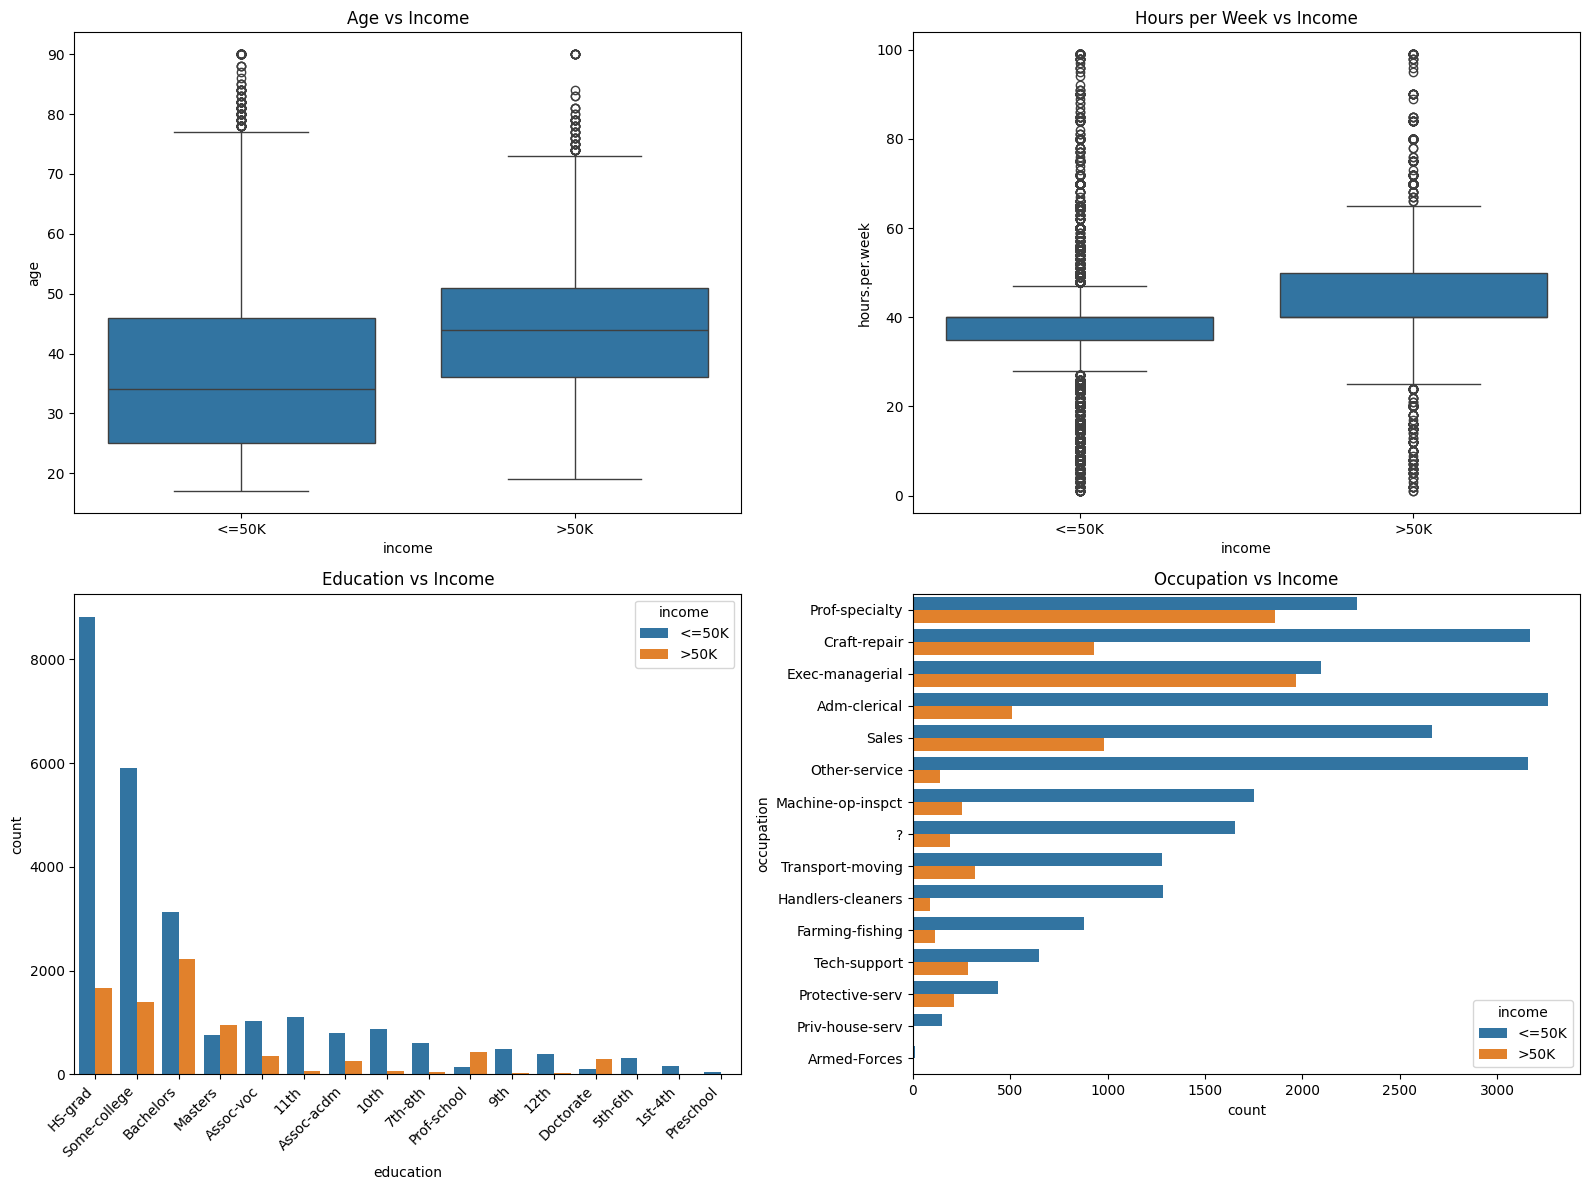

In [14]:
df['income_num'] = df['income'].map({'<=50K': 0, '>50K': 1})
plt.figure(figsize=(16, 12))

# 1. Age (numeric) vs income
plt.subplot(2, 2, 1)
sns.boxplot(x='income', y='age', data=df)
plt.title('Age vs Income')

# 2. Hours per week (numeric) vs income
plt.subplot(2, 2, 2)
sns.boxplot(x='income', y='hours.per.week', data=df)
plt.title('Hours per Week vs Income')

# 3. Education (categorical) vs income
plt.subplot(2, 2, 3)
sns.countplot(x='education', hue='income', data=df, order=df['education'].value_counts().index)
plt.xticks(rotation=45, ha='right')
plt.title('Education vs Income')

# 4. Occupation (categorical) vs income
plt.subplot(2, 2, 4)
sns.countplot(y='occupation', hue='income', data=df, order=df['occupation'].value_counts().index)
plt.title('Occupation vs Income')

plt.tight_layout()
plt.show()

In [15]:
print("Correlation between capital.gain and income_num:")
print(df[['capital.gain', 'income_num']].corr())

Correlation between capital.gain and income_num:
              capital.gain  income_num
capital.gain      1.000000    0.223329
income_num        0.223329    1.000000


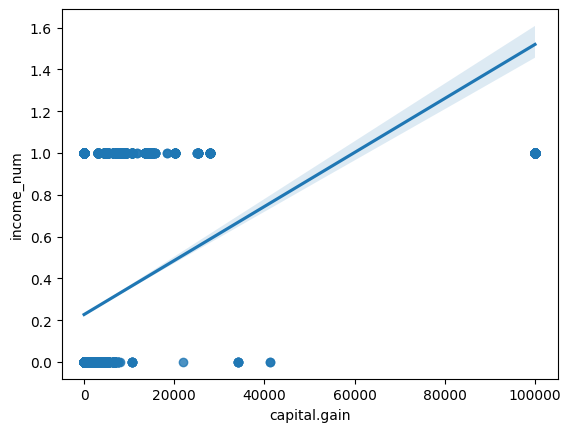

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

# regplot adds a linear regression line and confidence interval
sns.regplot(x=df['capital.gain'], y=df['income_num'], data=df)
plt.show()


Dataset

1)The Adult Census Income dataset contains 32,561 records and 15 columns of real 1994 US Census data. It is suitable for binary classification because the original collection purpose was to predict whether a person earns more than $50,000 per year.

2)The dataset has a good mix of numeric features (age, education.num, hours.per.week, capital.gain, capital.loss, fnlwgt) and categorical features (workclass, education, occupation, marital.status, etc.), which allows both statistical analysis and meaningful relationship exploration.

Data Quality

3)Three columns contain missing values originally stored as “?”: occupation (5.66%), workclass (5.64%), and native.country (1.79%). These missing values must be handled carefully later because simply dropping them would remove more than 5% of the data and could introduce bias.

4)There are 24 fully duplicated rows and no unique ID column. Keeping duplicates would give extra weight to the same individuals and slightly distort any model trained on the data.

5)The value 99999 in capital.gain is a sentinel (top-coded) value, not a real amount. Treating it as a normal number would exaggerate the effect of capital gains and mislead any model that uses this feature.

Target

6)The target variable income is moderately imbalanced (≤50K = 75.92%, >50K = 24.08%). A model that always predicts the majority class would already achieve ~76% accuracy, so accuracy alone is a misleading evaluation metric.

Relationships

7)Linear correlations between numeric features are all weak (maximum 0.15). However, capital.gain shows a strong non-linear relationship with income: almost all high values belong to the >50K class. Relying only on Pearson correlation would underestimate the importance of this feature.

8)Higher education level, older age, and longer working hours are clearly associated with higher income. These relationships are consistent with domain knowledge and give confidence that the data contains real signal.

Risks

9)Class imbalance risk: Because the target is imbalanced, a random train-test split or a model optimised only for accuracy can appear successful while performing poorly on the minority class (>50K). Stratified splitting and proper metrics (F1, recall, ROC-AUC) are required.

10)Missing value bias risk: occupation and workclass have more than 5% missing values. If these missing values are not random (for example, people with unstable jobs may be more likely to have missing occupation), simple imputation or listwise deletion can introduce systematic bias into the model.

11)Sentinel value / feature leakage risk: capital.gain contains the artificial value 99999. If this value is left untreated, the model can learn a spurious rule (“if capital.gain == 99999 then predict >50K”) that will not generalise to new data where the top-coding rule may be different.

Next Steps

Before modelling, the 24 duplicate rows should be removed, “?” should be converted to proper missing values, and a clear strategy for the three columns with missing data and the 99999 sentinel should be decided. Stratified sampling and class-weight or resampling techniques should be used to handle the imbalance.